## Explanations via Case Based Reasoning

Freeze backbone from ResNet trained in `ResNet_Train_Fungi.ipynb` and transform images in the latent space of the CNN.

The explanation will then be formulated on the basis of the $k$ nearest vectors.

In [1]:
!pwd
import sys
sys.path.append('./wingbeats/')

/mnt/KInsektDaten/teo


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from tensorflow.keras.layers.experimental.preprocessing import Rescaling

from beexplainable.beexplainable.modelling import classifiers as cls
from beexplainable.beexplainable.preprocessing import parsers as ps
from beexplainable.beexplainable.utils import metafile_readers as mr
from wingbeats import modelling as wm # for building simple classifiers

No module named 'nltk'


In [3]:
import tensorflow as tf
print(tf.__version__)

# Select GPU
print(tf.test.gpu_device_name())

gpus = tf.config.list_physical_devices('GPU')
print("Num GPUs available:", len(gpus))
try:
    tf.config.experimental.set_memory_growth(gpus[0], True) # don't allocate whole memory
except RuntimeError as e:
    print(e) # 'Invalid device or cannot modify virtual devices once initialized.'

2.8.1
/device:GPU:0
Num GPUs available: 1


2023-11-24 17:12:00.207680: I tensorflow/core/platform/cpu_feature_guard.cc:151] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  SSE4.1 SSE4.2 AVX AVX2 AVX512F FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2023-11-24 17:12:00.736534: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1525] Created device /device:GPU:0 with 46701 MB memory:  -> device: 0, name: Quadro RTX 8000, pci bus id: 0000:65:00.0, compute capability: 7.5


In [4]:
metafolder = './beexplainable/metafiles/Fungi/raw/toloka_CBR/' # same metafolder for masked and masked_bbox

CLASSES_PATH = metafolder + '/classes.txt'
FUNGI_PATH = '../data/DanishFungi/DF20M_3spec/'

IMAGES_PATH_NEIGHBORS = metafolder + 'images_neighbors.txt'
IMAGES_LABELS_PATH_NEIGHBORS = metafolder + 'image_class_labels_neighbors.txt'
IMAGES_PATH_TASK2 = metafolder + 'images_task2.txt'
IMAGES_LABELS_PATH_TASK2 = metafolder + 'image_class_labels_task2.txt'
SOFT_PREDS = './beexplainable/metafiles/Fungi/raw/softmax_preds.npy'

MODELS_PATH  = './beexplainable/models/'

### Load Images

In [5]:
#batch_size = 64
img_height = img_width = 224

**Note**: The neighbors in the 'training set' are all the Andrena samples from images_5_cleaned.txt without the 30 samples selected for the three Toloka tasks.

In [6]:
# Read file IDs and corresponding class labels of the set of neighbors
img_dict_neigh = mr.metafile_to_dict(IMAGES_PATH_NEIGHBORS)
img_label_dict_neigh = mr.metafile_to_dict(IMAGES_LABELS_PATH_NEIGHBORS)
file_ids_neigh = list( img_dict_neigh.keys() )
y_true_neigh   = list( img_label_dict_neigh.values() )
y_true_neigh   = np.asarray(y_true_neigh, dtype = np.uint8) - 1
# Note! Labels in CUB format start at index 1, but cross entropy needs to start at 0
print(str(len(y_true_neigh)) + ' neighbors')

# Read file IDs and corresponding class labels of the samples for Task 2
img_dict_t2 = mr.metafile_to_dict(IMAGES_PATH_TASK2)
img_label_dict_t2 = mr.metafile_to_dict(IMAGES_LABELS_PATH_TASK2)
file_ids_t2 = list( img_dict_t2.keys() )
y_true_t2   = list( img_label_dict_t2.values() )
y_true_t2   = np.asarray(y_true_t2, dtype = np.uint8) - 1
print(str(len(y_true_t2)) + ' samples in Task 2')

640 neighbors
10 samples in Task 2


In [7]:
classes = list( mr.metafile_to_dict(CLASSES_PATH).values() )
classes

['Russula_emetica', 'Russula_paludosa', 'Russula_rosea']

In [8]:
# Get dictionary of file IDs and file names
# Convert it into a tf.StaticHashTable to be able to retrieve dictionary values during eager execution
# Alternative: tf.gather
img_lookup = tf.lookup.StaticHashTable(tf.lookup.KeyValueTensorInitializer(file_ids_neigh, list(img_dict_neigh.values())),
                                       default_value = 'No file')

# Parsing function for tf.Dataset
parse_image_lab = lambda file_id, label: (ps.parse_image(file_id, img_lookup, img_width, img_height, FUNGI_PATH),
                                          label)

2023-11-24 17:12:00.815278: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1525] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 46701 MB memory:  -> device: 0, name: Quadro RTX 8000, pci bus id: 0000:65:00.0, compute capability: 7.5


In [9]:
# Conversion to tf.Dataset
train_set = ps.parse_to_dataset(file_ids_neigh, y_true_neigh, parse_image_lab)
train_set = train_set.cache().prefetch(tf.data.experimental.AUTOTUNE)

# Normalize raw images
normalization_layer = Rescaling(1./255)
train_set = train_set.map(lambda x, y: (normalization_layer(x), y))

In [10]:
# Create dataset for the test samples, too
img_lookup = tf.lookup.StaticHashTable(tf.lookup.KeyValueTensorInitializer(file_ids_t2, list(img_dict_t2.values())),
                                       default_value = 'No file')

# Parsing function for tf.Dataset
parse_image_lab = lambda file_id, label: (ps.parse_image(file_id, img_lookup, img_width, img_height, FUNGI_PATH), label)

# Conversion to tf.Dataset
test_set = ps.parse_to_dataset(file_ids_t2, y_true_t2, parse_image_lab)
test_set = test_set.cache().prefetch(tf.data.experimental.AUTOTUNE)
test_set = test_set.map(lambda x, y: (normalization_layer(x), y))

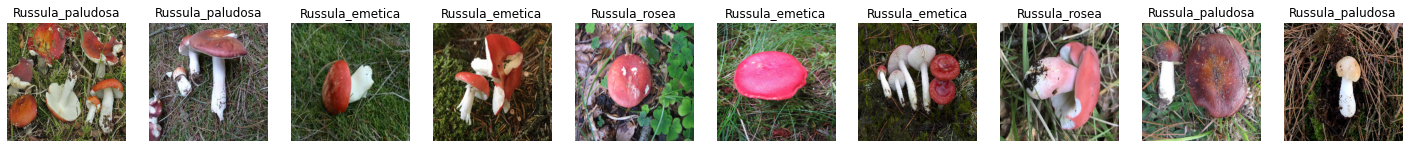

In [11]:
# Plot test samples
plt.figure(figsize = (25, 10))
num_cols = len(y_true_t2)
with tf.device('/CPU:0'):
    i = 1
    for img, lab in test_set:
        plt.subplot(1, num_cols, i)
        plt.imshow(img)
        plt.title(classes[lab.numpy()])
        plt.axis("off")
        i += 1
plt.show()

### Load Model

In [12]:
# Define initial training and other model parameters
epochs, drop_rate = 10, 0.5
lr, reg = 1e-3, 1e-3 # parameters optimized in HPO notebook
in_shape = (img_width, img_height, 3)

constructor, out_shape =  wm.build_simple_classifier, len(classes)
loss = 'sparse_categorical_crossentropy'
metrics = ['accuracy']

# Define whether to load fine grained backbone weights
load_pretrained_backbone = True # if False, ImageNet weights are loaded
# ResNet50 weights trained on iNat2021
# https://github.com/visipedia/newt/tree/main/benchmark
pretrained_weights_file = MODELS_PATH + 'backbones/resnet50_simclr_v1_inat20_no_top_500.h5' if load_pretrained_backbone else None

# Derive model name
input_form = 'raw' # raw, masked, bbox, masked_bbox
init = 'iNat' if load_pretrained_backbone else 'Imagenet'
model_name = 'ResNet50_' + init + '_' + input_form + '_Fungi'
print(model_name)

# The pretrained ResNet on iNat already has a GlobalAvgPooling layer
add_global_avg = False if load_pretrained_backbone else True

# Whether to retrain the backbone or not
trainable = True

ResNet50_iNat_raw_Fungi


In [13]:
# Build and compile
tf.keras.backend.clear_session()
cnn_name = 'CNN_Blocks_' + model_name

cnn = cls.CNN_ResNet50(in_shape, drop_rate, add_global_avg = add_global_avg, trainable = trainable,
                       weights_file = pretrained_weights_file, name = cnn_name)

model = constructor(in_shape, out_shape, cnn, reg,
                    input_name = 'jpg', model_name = model_name)

model.load_weights(MODELS_PATH + 'all/Fungi/' + model_name + '/' + model_name + '.h5',
                   by_name = True, skip_mismatch = True)

model.compile(tf.keras.optimizers.Adam(lr), loss = loss, metrics = metrics)

### XAI: Pick nearest neighbors from training set in feature space

In [14]:
# Extract features of the training set with ResNet backbone
res_concepts = []
i = 0
for img, lab in train_set:
    res_concepts.append( cnn.resnet.predict(tf.expand_dims(img, axis=0)) )
    i += 1
    if i % 100 == 0: print(str(i) + ' done')
res_concepts = tf.squeeze(res_concepts, axis=1)
tf.shape(res_concepts)

2023-11-24 17:12:04.259753: I tensorflow/stream_executor/cuda/cuda_dnn.cc:368] Loaded cuDNN version 8401
2023-11-24 17:12:04.751178: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2023-11-24 17:12:04.752315: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2023-11-24 17:12:04.752326: W tensorflow/stream_executor/gpu/asm_compiler.cc:80] Couldn't get ptxas version string: INTERNAL: Couldn't invoke ptxas --version
2023-11-24 17:12:04.753439: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2023-11-24 17:12:04.753587: W tensorflow/stream_executor/gpu/redzone_allocator.cc:314] INTERNAL: Failed to launch ptxas
Relying on driver to perform ptx compilation. 
Modify $PATH to customize ptxas location.
This message will be only logged once.


100 done
200 done
300 done
400 done
500 done
600 done


<tf.Tensor: shape=(2,), dtype=int32, numpy=array([ 640, 2048], dtype=int32)>

In [15]:
# Extract features for the test set
test_features = []
for img, lab in test_set:
    test_features.append( cnn.resnet.predict(tf.expand_dims(img, axis=0)) )

In [16]:
# Fit NN on CNN activations
neigh = NearestNeighbors(n_neighbors=3)
neigh.fit(res_concepts)

NearestNeighbors(n_neighbors=3)

In [17]:
# Predictions for test samples were computed previously (see slides)
test_preds = [0, 1, 1, 0, 2, 0, 0, 2, 1, 1]
# Get file ids for all neighbors
# Note: since Toloka samples were removed from images_neighbors.txt, there are some indexes missing!
neigh_keys = list(img_dict_neigh.keys())
# Load precomputed softmax predictions
loaded_soft = np.load(SOFT_PREDS)

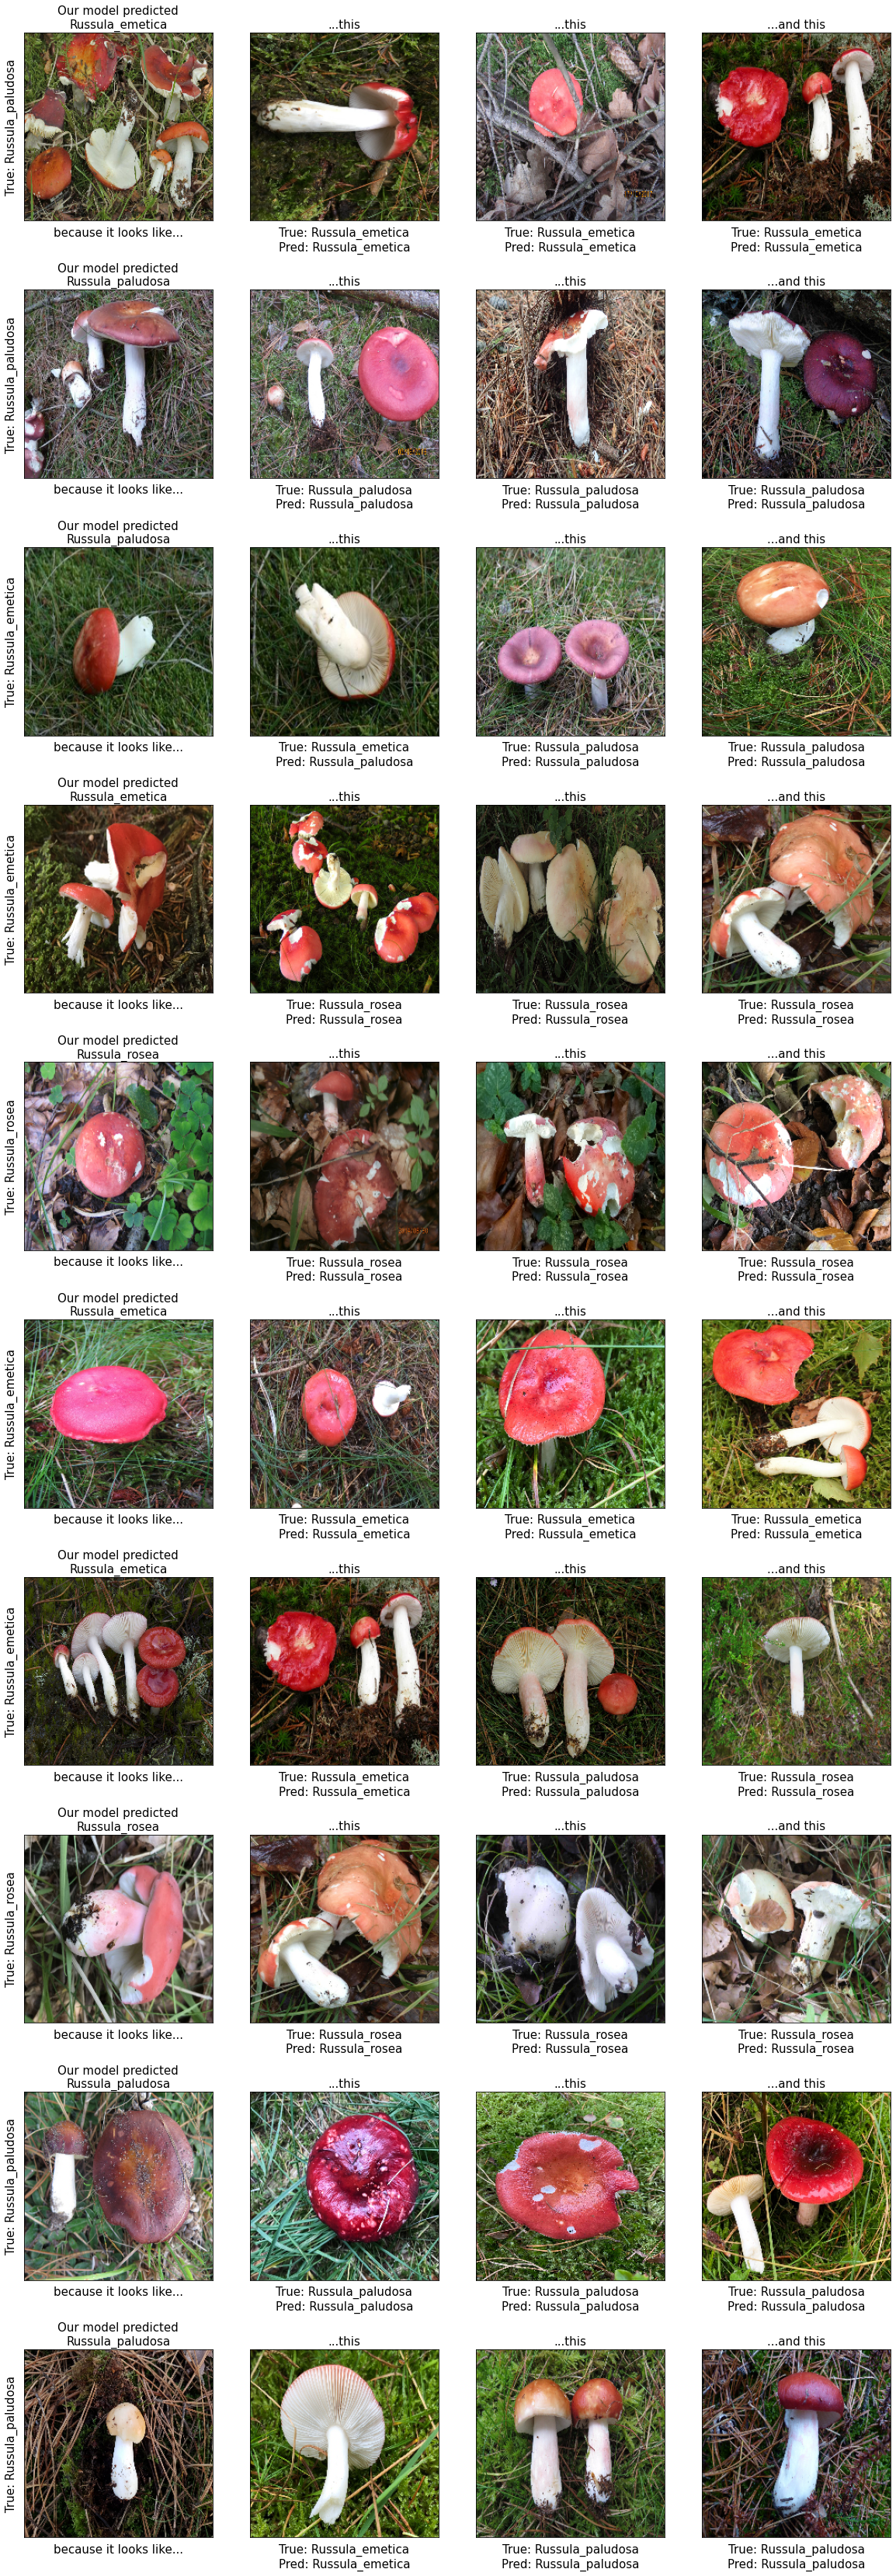

In [18]:
# Explain every test samples via ita k nearest neighbors in the CNN feature space
test_ind = 1
title_size = 15
num_cols, num_rows = neigh.n_neighbors+1, len(y_true_t2)
plt.figure(figsize=(20, 60))
for img, lab in test_set:

    # Get feature vector of current test sample
    test_activation = test_features[test_ind//num_cols]

    # Find the indexes of the k nearest neighbors
    kn_ind = neigh.kneighbors(test_activation, return_distance = False)[0]

    # Display original test image
    plt.subplot(num_rows, num_cols, test_ind)
    plt.imshow(img)
    plt.title('Our model predicted\n' + classes[test_preds[test_ind//num_cols]], fontsize=title_size)
    plt.xlabel('because it looks like...', fontsize=title_size); plt.xticks([]); plt.yticks([])
    plt.ylabel('True: ' + classes[lab], fontsize=title_size)

    # Get the corresponding images of the neighbors
    for i, k in enumerate(kn_ind):
        y_pred = np.argmax( loaded_soft[ int(neigh_keys[k])-1 ], axis=-1 ) # prediction for current neighbor
        for img, lab in train_set.skip(k).take(1):
            plt.subplot(num_rows, num_cols, test_ind+i+1)
            plt.imshow(img)
            plt.title('...and this' if i == len(kn_ind)-1 else '...this', fontsize=title_size)
            plt.xticks([]); plt.yticks([])
            plt.xlabel('True: ' + classes[lab] + '\nPred: ' + classes[y_pred], fontsize=title_size)
    test_ind += num_cols
plt.show()